# Recovering ring-2 stimulus angle from the ring-1 region

In the `patched_wiring` network from notebook 02 (50×50 torus, d = 10, seed 0), each input group reaches only its own patch. Ring 2's sixteen inputs never touch the ring-1 patch. **Can the ring-2 stimulus angle still be read out linearly from the ring-1 patch, and when?**

Whatever reaches ring 1 must travel through recurrence. The two ring patches are about 11 units apart, edge to edge, so at d = 10 the information takes at least 2 recurrent steps (200 ms).

**Trials.** The 42 single-bump tasks: the go/anti family and the match family (dms/dnms/dmc/dnmc), including their int and seq variants. Each puts its one stimulus on ring 1 or ring 2 at random. Each task runs 128 trials as one stream, the way training and evaluation do. The decoded variable is the first stimulus's true angle, taken from the trial record. In match tasks, that is the sample, so the later steps test whether it survives the delay.

**Decoder.** At each step τ relative to stimulus onset, a ridge regression from a region's unit activity to (cos θ, sin θ) is fit and scored on held-out trials. It uses 5-fold cross-validation stratified by task, with per-unit z-scoring and ridge strength fit on training folds only. The score is the fraction of held-out trials decoded within ±22.5° (one ring unit), where chance is 0.125. The null is 20 refits with shuffled angles, and we show its 95th percentile.

**Regions.**

| region | trials | role |
|---|---|---|
| `ring1` | ring 2 | **the question**: the ring-1 patch (324 units) |
| `ring2` | ring 2 | ceiling: the patch that receives the stimulus |
| `ring1_self` | ring 1 | reference: the ring-1 patch decoding its own input |
| `ring1_near` / `matched` | ring 2 | paired control: 160 ring-1 units, each paired with an input-free unit at the same distance from the ring-2 patch (within 0.5) |

Ring 1 is the part of the sheet farthest from ring 2. No unit outside it is more than 17.5 units from the ring-2 patch, while ring-1 units reach 22.6. So the distance-matched control can only pair ring 1's nearer units.

Running this notebook takes about 8 minutes, mostly the shuffle null. The model weights are git-ignored. To regenerate them, run `python -m cortical.train --condition patched_wiring --seed 0` (notebook 02).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Circle, Rectangle

from cogtasks import make_task
from cogtasks.modcog._envs import _Reach
from cortical.decode import HIT_TOLERANCE, circular_error, collect, decode_over_time, regions
from cortical.model import MaskedRNN
from cortical.wiring import LAYOUT_B_LARGE, input_mask

L, D = 50, 10
MODEL = "../results/02_input_patches/patched_wiring_s0/model.pt"
SURFACE, INK, MUTED, RULE = "#fcfcfb", "#0b0b0b", "#52514e", "#c3c2b7"
COLORS = {  # categorical slots 1-5, validated; every line also carries a text label
    "ring1": "#2a78d6",
    "ring2": "#eb6834",
    "ring1_self": "#1baf7a",
    "ring1_near": "#eda100",
    "matched": "#e87ba4",
}
LABELS = {
    "ring1": "ring-1 patch (ring-2 trials)",
    "ring2": "ring-2 patch (ceiling)",
    "ring1_self": "ring-1 patch, own input (ring-1 trials)",
    "ring1_near": "ring-1 near units (160)",
    "matched": "distance-matched input-free (160)",
}
CHANCE = 1 / 8
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "text.color": INK,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.edgecolor": RULE,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 9,
    }
)

device = "mps" if torch.backends.mps.is_available() else "cpu"
model = MaskedRNN(L, D, input_mask(L, LAYOUT_B_LARGE))
model.load_state_dict(torch.load(MODEL, map_location="cpu"))
model = model.to(device).eval()
units_by_region = regions(L, LAYOUT_B_LARGE)
recorded = np.unique(np.concatenate(list(units_by_region.values())))
trials = collect(model, units=recorded, device=device)
n_ring1, n_ring2 = np.sum(trials.modality == 1), np.sum(trials.modality == 2)
print(f"{len(trials.task)} trials: {n_ring1} ring-1, {n_ring2} ring-2")

5376 trials: 2688 ring-1, 2688 ring-2


## Where the regions sit

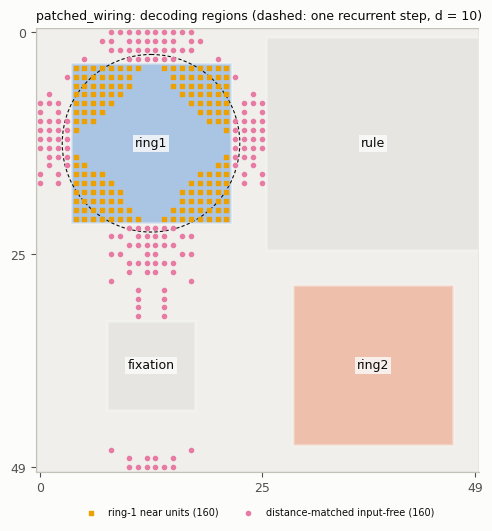

In [2]:
fig, ax = plt.subplots(figsize=(5.2, 5.2), layout="constrained")
ax.set_xlim(-0.5, L - 0.5)
ax.set_ylim(L - 0.5, -0.5)
ax.set_aspect("equal")
ax.add_patch(Rectangle((-0.5, -0.5), L, L, facecolor="#f0efec", edgecolor=RULE))
for group, (centre, size) in LAYOUT_B_LARGE.items():
    x0, y0 = centre[0] - size / 2, centre[1] - size / 2
    color = {"ring1": COLORS["ring1"], "ring2": COLORS["ring2"]}.get(group, "#d6d4cf")
    ax.add_patch(
        Rectangle((x0, y0), size, size, facecolor=color, alpha=0.35, edgecolor=SURFACE, lw=2)
    )
    ax.text(
        *centre,
        group,
        ha="center",
        va="center",
        fontsize=9,
        color=INK,
        bbox={"facecolor": SURFACE, "edgecolor": "none", "alpha": 0.8, "pad": 1.5},
    )
for name, marker in (("ring1_near", "s"), ("matched", "o")):
    y, x = np.divmod(units_by_region[name], L)
    ax.scatter(x, y, s=9, marker=marker, color=COLORS[name], label=LABELS[name], zorder=3)
ax.add_patch(Circle((12.5, 12.5), D, facecolor="none", edgecolor=INK, lw=0.8, ls=(0, (3, 2))))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncols=2, frameon=False, fontsize=7)
ax.set_xticks([0, 25, 49])
ax.set_yticks([0, 25, 49])
ax.set_title(
    "patched_wiring: decoding regions (dashed: one recurrent step, d = 10)", loc="left", fontsize=9
)
plt.show()

## Decoding over time

Each region gets one decoder per step τ, at 100 ms per step. τ = 0 is the first step the stimulus is on the input. The grey band runs from chance up to the shuffle null's 95th percentile (the highest across regions).

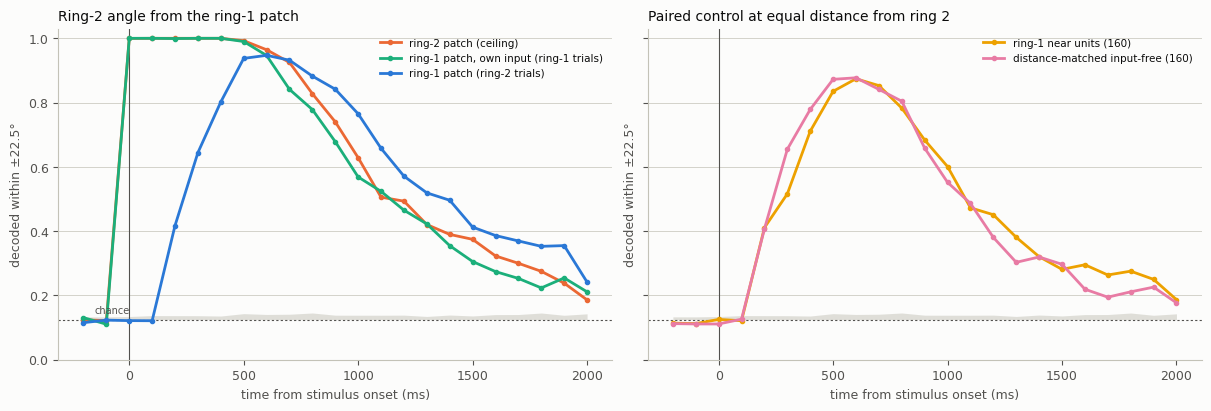

accuracy at τ (ms) =                        0    200    300    500   1000   1500   2000
ring-1 patch (ring-2 trials)             0.12   0.42   0.64   0.94   0.76   0.41   0.24
ring-2 patch (ceiling)                   1.00   1.00   1.00   0.99   0.63   0.37   0.19
ring-1 patch, own input (ring-1 trials)   1.00   1.00   1.00   0.99   0.57   0.31   0.21
ring-1 near units (160)                  0.13   0.41   0.52   0.84   0.60   0.28   0.19
distance-matched input-free (160)        0.11   0.41   0.65   0.87   0.55   0.30   0.18
shuffle null (95th pct, max over regions)   0.13   0.14   0.14   0.14   0.14   0.14   0.14


In [3]:
def run(name):
    on = trials.modality == (1 if name == "ring1_self" else 2)
    cols = np.searchsorted(recorded, units_by_region[name])
    return decode_over_time(
        trials.activity[on][:, :, cols], trials.angle[on], trials.valid[on], trials.task[on], seed=0
    ), on


results = {name: run(name) for name in COLORS}
tau_ms = results["ring1"][0].tau * 100
null = np.max([r.null95 for r, _ in results.values()], axis=0)


def panel(ax, names, title):
    ax.fill_between(tau_ms, CHANCE, null, color=RULE, alpha=0.5, lw=0)
    ax.axhline(CHANCE, color=MUTED, lw=0.8, ls=(0, (2, 2)))
    ax.axvline(0, color=MUTED, lw=0.8)
    for name in names:
        r = results[name][0]
        ax.plot(tau_ms, r.accuracy, color=COLORS[name], lw=2, marker="o", ms=3, label=LABELS[name])
    ax.set_ylim(0, 1.03)
    ax.set_xlabel("time from stimulus onset (ms)")
    ax.set_ylabel("decoded within ±22.5°")
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(axis="y", color=RULE, lw=0.5)
    ax.legend(loc="upper right", frameon=False, fontsize=7.5)


fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained", sharey=True)
panel(left, ("ring2", "ring1_self", "ring1"), "Ring-2 angle from the ring-1 patch")
panel(right, ("ring1_near", "matched"), "Paired control at equal distance from ring 2")
left.text(-150, CHANCE + 0.02, "chance", fontsize=7, color=MUTED)
plt.show()

steps = [0, 2, 3, 5, 10, 15, 20]
print(f"{'accuracy at τ (ms) =':38s}" + "".join(f"{s * 100:>7d}" for s in steps))
for name in COLORS:
    r = results[name][0]
    print(f"{LABELS[name]:38s}" + "".join(f"{r.accuracy[r.tau == s][0]:7.2f}" for s in steps))
print(
    f"{'shuffle null (95th pct, max over regions)':38s}"
    + "".join(f"{null[results['ring1'][0].tau == s][0]:7.2f}" for s in steps)
)

## By task family

The same pooled decoders, scored separately on go/anti trials and match trials. Go/anti stimuli last 500 ms (the `rt*` tasks keep them on until the response). Match tasks show a 500 ms sample, then a delay of 200–1200 ms (it varies by trial), then a test stimulus at a different or the same angle.

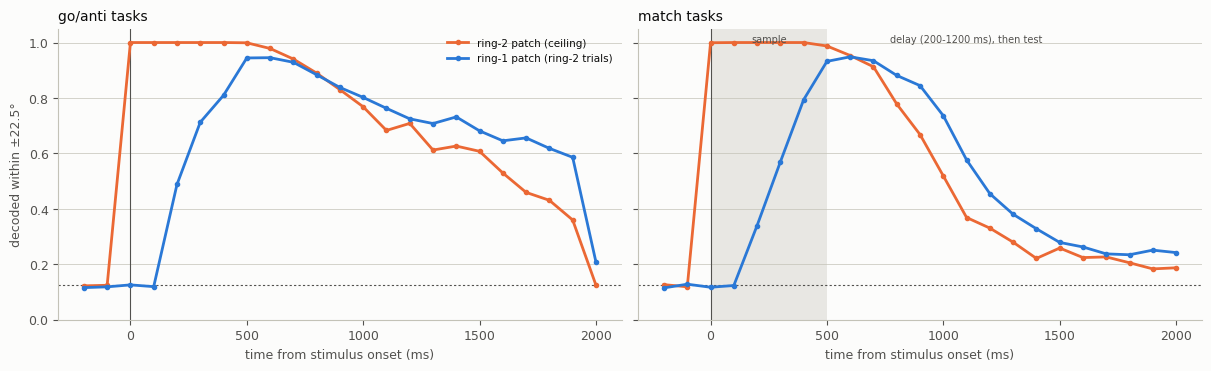

In [4]:
def task_family(task):
    return "go/anti" if isinstance(make_task("modcog", task).unwrapped, _Reach) else "match"


family = np.array([task_family(t) for t in trials.task])


def family_accuracy(name, fam):
    r, on = results[name]
    rows = family[on] == fam
    pred, truth = r.predicted[rows], trials.angle[on][rows][:, None]
    valid = ~np.isnan(pred)
    hits = (circular_error(np.nan_to_num(pred), truth) <= HIT_TOLERANCE) & valid
    return hits.sum(0) / np.maximum(valid.sum(0), 1)


fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained", sharey=True)
for ax, fam in zip(axes, ("go/anti", "match"), strict=True):
    ax.axhline(CHANCE, color=MUTED, lw=0.8, ls=(0, (2, 2)))
    ax.axvline(0, color=MUTED, lw=0.8)
    if fam == "match":
        ax.axvspan(0, 500, color=RULE, alpha=0.35, lw=0)
        ax.text(250, 1.0, "sample", ha="center", fontsize=7, color=MUTED)
        ax.text(1100, 1.0, "delay (200-1200 ms), then test", ha="center", fontsize=7, color=MUTED)
    for name in ("ring2", "ring1"):
        ax.plot(
            tau_ms,
            family_accuracy(name, fam),
            color=COLORS[name],
            lw=2,
            marker="o",
            ms=3,
            label=LABELS[name],
        )
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{fam} tasks", loc="left", fontsize=10)
    ax.set_xlabel("time from stimulus onset (ms)")
    ax.grid(axis="y", color=RULE, lw=0.5)
axes[0].set_ylabel("decoded within ±22.5°")
axes[0].legend(loc="upper right", frameon=False, fontsize=7.5)
plt.show()

## What we see

- **Yes: the ring-2 angle reaches the ring-1 patch, starting 200 ms after onset.** At τ = 0 and 100 ms, decoding from the ring-1 patch sits at chance (0.12). It rises to 0.42 at 200 ms and 0.64 at 300 ms, and peaks at 0.94–0.95 at 500–600 ms. The two-step lag is what the geometry predicts: the patches are about 11 units apart, and recurrence covers at most 10 per step.
- **Once there, the information is as good as at the source, and it lasts longer.** By 500–600 ms the ring-1 patch matches the ring-2 patch (0.94–0.95 against 0.96–0.99). After about 700 ms the ring-1 patch holds the angle **better** than the ring-2 patch itself: 0.76 against 0.63 at 1 s, and 0.41 against 0.37 at 1.5 s. In match tasks the gap shows earlier: 0.88 against 0.78 at 800 ms. As the stimulus ends, the source patch forgets faster than the region the information spread into. Ring 1 decodes its *own* stimulus perfectly from the first step (`ring1_self`: 1.00), the same as ring 2 does for ring-2 stimuli.
- **Ring 1 is not special; distance is what matters.** Ring-1 units and input-free units at the same distance from ring 2 carry about the same information: 0.41 against 0.41 at 200 ms, and 0.84 against 0.87 at 500 ms, with 160 units each. The full ring-1 patch decodes better than its 160 nearer units (0.94 against 0.84 at 500 ms), probably because a larger population gives the decoder more units to average over.
- **Go/anti tasks keep the angle longer than match tasks.** In go/anti tasks the ring-1 patch still decodes it at 0.6–0.7 from 1.2 to 1.9 s after onset. In match tasks the sample angle fades through the delay, to about 0.25 by 1.5–2 s, and the ring-2 patch's fades to about 0.2. Wherever the network keeps the sample for the full delay, it isn't kept as a linearly readable angle in either ring patch.


## Caveats

- **One network, one seed.** The arrival time and the paired-control comparison should be checked on more seeds.
- **Linear decoding only.** Information that is present but not linearly readable would be missed.
- **Decodable is not the same as used.** These results show that ring-2 information *reaches* ring 1, not that the network relies on it there. That would take a causal test, such as silencing ring 1 on ring-2 trials.
- **The late steps mix stimuli.** For match tasks, the late steps include the test stimulus, which sits at the sample's angle on match trials and elsewhere on non-match trials. They also include trials of different lengths, so fewer trials enter each late step.